# 01 · Exploración inicial y definición del objetivo

**Pregunta:** ¿qué tan seguido una licitación pública queda **desierta** y de qué depende? De aquí sale el objetivo del modelo (P1.7).

Datos: warehouse dbt-duckdb (`dbt build` antes de correr). Listados de ~69 mil licitaciones (abr–oct 2026) y una primera muestra de detalle.

*Fuente: Dirección ChileCompra.*

In [1]:
import os, duckdb, matplotlib.pyplot as plt, matplotlib.ticker as mt
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)  # las vistas de staging leen data/raw con rutas relativas a la raíz
con = duckdb.connect(str(ROOT / "data/warehouse.duckdb"), read_only=True)
IMG = ROOT / "docs/img"; IMG.mkdir(parents=True, exist_ok=True)

# Paleta validada (orden categórico fijo) y tinta de texto
AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
TXT, TXT2, GRID, FONDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": GRID, "axes.labelcolor": TXT2, "xtick.color": TXT2, "ytick.color": TXT2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlecolor": TXT, "axes.titlelocation": "left",
})
FUENTE = "Fuente: Dirección ChileCompra"

def pie(fig):
    fig.text(0.01, 0.005, FUENTE, fontsize=8, color=TXT2)

q = lambda s: con.sql(s).df()

## 1. Una fila por licitación

El listado diario no es "publicadas ese día": cada licitación aparece el día de su **último evento** (publicación, cierre o adjudicación). Para contar licitaciones se toma su aparición más reciente.

In [2]:
con.sql('''create or replace temp view lic as
  select * from stg_listados
  qualify row_number() over (partition by codigo order by fecha_listado desc) = 1''')
estados = q("select estado, count(*) n, round(100.0*count(*)/sum(count(*)) over(), 1) pct from lic group by 1 order by n desc")
estados

,estado,n,pct
0,adjudicada,40370,58.4
1,desierta,10550,15.3
2,cerrada,9520,13.8
3,publicada,4562,6.6
4,revocada,4008,5.8
5,suspendida,63,0.1


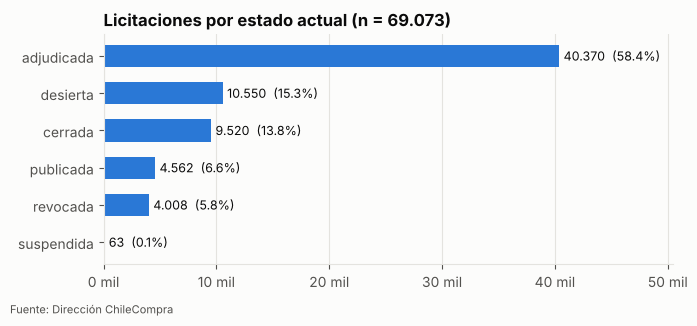

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.2))
e = estados.iloc[::-1]
ax.barh(e.estado, e.n, color=AZUL, height=0.6)
for y, (n, p) in enumerate(zip(e.n, e.pct)):
    ax.text(n + 400, y, f"{n:,.0f}  ({p}%)".replace(",", "."), va="center", fontsize=9, color=TXT)
ax.set_title(f"Licitaciones por estado actual (n = {estados.n.sum():,.0f})".replace(",", "."))
ax.xaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: f"{v/1000:.0f} mil"))
ax.grid(axis="y", visible=False); ax.set_xlim(0, e.n.max() * 1.25)
pie(fig); fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(IMG / "eda_estados.png", dpi=150)

## 2. Composición por mes y censura

Mes = mes del último evento. Las licitaciones recientes siguen **abiertas** (publicadas o cerradas sin resolver), así que los últimos meses están censurados: si se calculara la tasa de desiertas sobre el total, bajaría artificialmente. Por eso la tasa se calcula solo entre las que **tienen resultado** (adjudicada o desierta).

In [4]:
mes = q('''select strftime(fecha_listado, '%Y-%m') mes,
   count(*) filter (where estado='adjudicada') adjudicada,
   count(*) filter (where estado='desierta')   desierta,
   count(*) filter (where estado in ('publicada','cerrada')) abierta,
   count(*) filter (where estado in ('revocada','suspendida')) revocada_suspendida
 from lic group by 1 order by 1''')
mes["pct_desierta"] = (100 * mes.desierta / (mes.adjudicada + mes.desierta)).round(1)
mes

,mes,adjudicada,desierta,abierta,revocada_suspendida,pct_desierta
0,2026-04,6464,1583,155,593,19.7
1,2026-05,5576,1567,229,536,21.9
2,2026-06,6529,1669,394,654,20.4
3,2026-07,6539,1658,638,881,20.2
4,2026-08,6159,1668,1531,614,21.3
5,2026-09,6422,1711,5009,568,21.0
6,2026-10,2681,694,6126,225,20.6


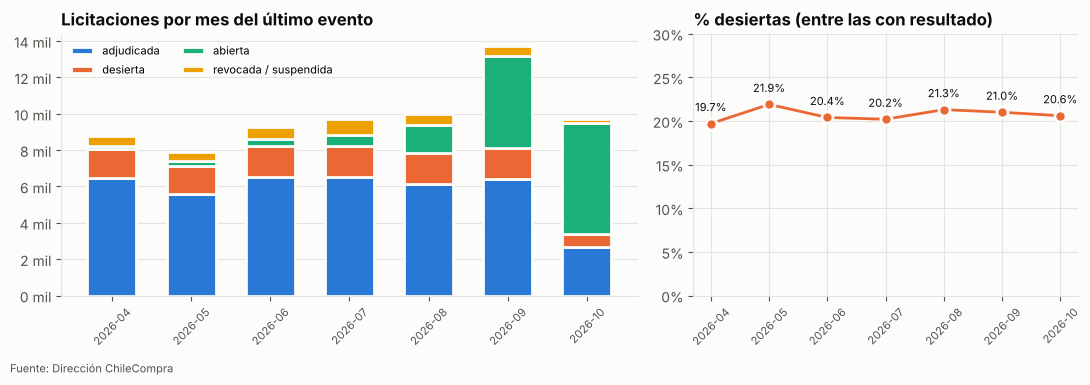

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [3, 2]})
series = [("adjudicada", AZUL), ("desierta", NARANJA), ("abierta", AQUA), ("revocada_suspendida", AMARILLO)]
base = 0
for col, colr in series:
    a1.bar(mes.mes, mes[col], bottom=base, color=colr, width=0.62, edgecolor=FONDO, linewidth=2,
           label=col.replace("_", " / "))
    base = base + mes[col]
a1.set_title("Licitaciones por mes del último evento")
a1.yaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: f"{v/1000:.0f} mil"))
a1.legend(frameon=False, fontsize=8, loc="upper left", ncol=2); a1.grid(axis="x", visible=False)

a2.plot(mes.mes, mes.pct_desierta, color=NARANJA, lw=2, marker="o", ms=8, mec=FONDO, mew=2)
for x, y in zip(mes.mes, mes.pct_desierta):
    a2.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8, color=TXT)
a2.set_ylim(0, 30); a2.yaxis.set_major_formatter(mt.PercentFormatter(decimals=0))
a2.set_title("% desiertas (entre las con resultado)")
for a in (a1, a2): a.tick_params(axis="x", labelsize=8, rotation=45)
pie(fig); fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(IMG / "eda_meses.png", dpi=150)

**Lectura:** la tasa de desiertas es muy estable (~20–22% cada mes) aunque la censura crece hacia octubre. Es una base sólida: el objetivo no depende de la estación ni se distorsiona con los meses recientes si se mide solo entre licitaciones resueltas.

## 3. Tipo de licitación

In [6]:
tipo = q('''select tipo, count(*) filter (where estado in ('adjudicada','desierta')) n,
   round(100.0*count(*) filter (where estado='desierta') / nullif(count(*) filter (where estado in ('adjudicada','desierta')),0), 1) pct_desierta
 from lic group by 1 having n >= 200 order by pct_desierta''')
tipo

,tipo,n,pct_desierta
0,R1,984,3.2
1,O1,569,16.0
2,LP,9825,16.8
3,LR,3014,16.9
4,LE,28169,20.4
5,L1,6686,26.7
6,B2,279,43.7
7,CO,984,45.7


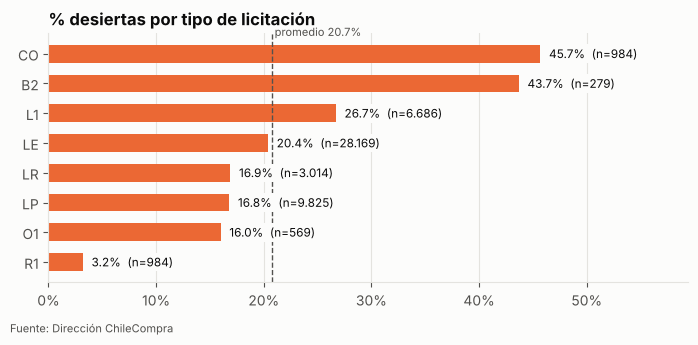

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.4))
global_pct = 100 * mes.desierta.sum() / (mes.adjudicada.sum() + mes.desierta.sum())
ax.barh(tipo.tipo, tipo.pct_desierta, color=NARANJA, height=0.6)
for y, (p, n) in enumerate(zip(tipo.pct_desierta, tipo.n)):
    ax.text(p + 0.8, y, f"{p:.1f}%  (n={n:,.0f})".replace(",", "."), va="center", fontsize=8.5, color=TXT,
            bbox=dict(facecolor=FONDO, edgecolor="none", pad=1.5), zorder=3)
ax.axvline(global_pct, color=TXT2, lw=1, ls="--", zorder=1)
ax.text(global_pct, len(tipo) - 0.4, f" promedio {global_pct:.1f}%", fontsize=8, color=TXT2)
ax.set_title("% desiertas por tipo de licitación"); ax.set_xlim(0, tipo.pct_desierta.max() * 1.3)
ax.xaxis.set_major_formatter(mt.PercentFormatter(decimals=0)); ax.grid(axis="y", visible=False)
pie(fig); fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(IMG / "eda_tipos.png", dpi=150)

Tipos según el código: **L1** < 100 UTM, **LE** 100–1.000 UTM, **LP** > 1.000 UTM, **LR** > 5.000 UTM, **CO/B2/O1** otros procedimientos, **R1** órdenes de compra menores. Las licitaciones chicas (L1) y los procedimientos especiales (CO, B2) quedan desiertas mucho más seguido que las grandes.

## 4. Rubro y organismo (muestra de detalle)

El detalle se está descargando de noche; por ahora cubre solo parte de abril, así que estos números son preliminares.

In [8]:
cob = q("select count(*) n, min(fecha_publicacion)::date desde, max(fecha_publicacion)::date hasta from fct_licitaciones")
rub = q('''select rubro, n_con_resultado n, round(100*tasa_desierta, 1) pct_desierta, oferentes_mediana
 from dim_rubros where n_con_resultado >= 100 order by pct_desierta''')
cob, rub

(      n      desde      hasta
 0  5756 2014-06-23 2026-04-21,
                                                 rubro    n  pct_desierta  \
 0              Medicamentos y productos farmacéuticos  284           8.5   
 1                  Equipamiento y suministros médicos  653          12.7   
 2                      Equipamiento para laboratorios  135          13.3   
 3          Salud, servicios sanitarios y alimentación  212          15.6   
 4                    Servicios de limpieza industrial  141          17.0   
 5   Servicios profesionales, administrativos y con...  428          17.3   
 6   Servicios editoriales, de diseño, publicidad, ...  100          18.0   
 7   Tecnologías de la información, telecomunicacio...  216          20.4   
 8   Artículos para estructuras, obras y construcci...  166          20.5   
 9                 Vehículos y equipamiento en general  129          22.5   
 10          Servicios de construcción y mantenimiento  552          24.1   
 11       Ser

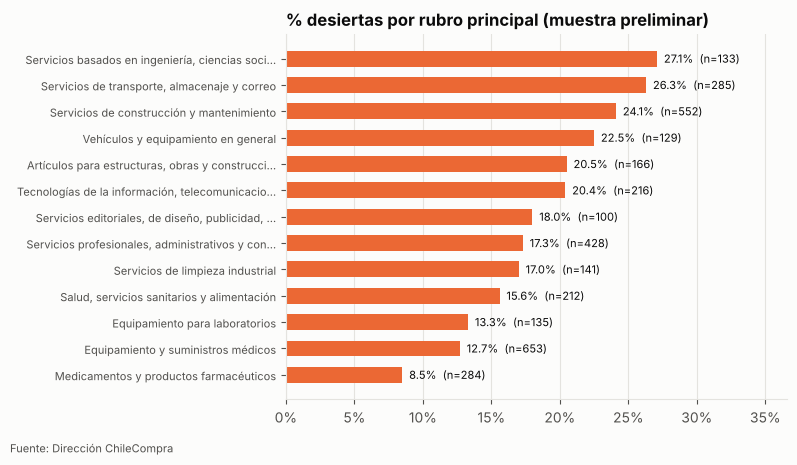

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.6))
etiq = [r if len(r) <= 48 else r[:46] + "…" for r in rub.rubro]
ax.barh(etiq, rub.pct_desierta, color=NARANJA, height=0.6)
for y, (p, n) in enumerate(zip(rub.pct_desierta, rub.n)):
    ax.text(p + 0.5, y, f"{p:.1f}%  (n={n})", va="center", fontsize=8, color=TXT)
ax.set_title("% desiertas por rubro principal (muestra preliminar)")
ax.set_xlim(0, rub.pct_desierta.max() * 1.35); ax.xaxis.set_major_formatter(mt.PercentFormatter(decimals=0))
ax.tick_params(axis="y", labelsize=8); ax.grid(axis="y", visible=False)
pie(fig); fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(IMG / "eda_rubros.png", dpi=150)

In [10]:
# Relación con la competencia: oferentes en adjudicadas vs. desiertas
q('''select estado, count(*) n, round(avg(numero_oferentes), 2) promedio,
        quantile_cont(numero_oferentes, 0.5) mediana,
        round(100.0*avg((numero_oferentes = 0)::int), 1) pct_cero_ofertas
 from fct_licitaciones where tiene_resultado group by 1''')

,estado,n,promedio,mediana,pct_cero_ofertas
0,desierta,1040,1.86,1.0,31.2
1,adjudicada,4242,4.81,3.0,0.0


**Lectura:** en la muestra, solo ~31% de las desiertas no recibió ninguna oferta; el resto recibió ofertas (mediana 1) que fueron rechazadas o declaradas inadmisibles. "Desierta" no equivale a "sin interés del mercado": también captura bases difíciles de cumplir o presupuestos insuficientes. Es una razón más para modelar al publicar, cuando el comprador aún puede ajustar.

## 5. Definición del objetivo

| Decisión | Elección | Por qué |
|---|---|---|
| Objetivo | `es_desierta` (binario) | Estable (~21%), relevante para el comprador y con datos suficientes |
| Población | licitaciones con resultado (adjudicada o desierta) | Revocadas/suspendidas son decisiones del organismo, no falta de ofertas |
| Momento de predicción | **al publicar** | Para que sirva al comprador mientras aún puede ajustar plazos o bases |
| Variables prohibidas (fuga) | `numero_oferentes`, fechas y montos de adjudicación, estado | Se conocen después del cierre |
| Split | temporal por `fecha_publicacion` | Evita mezclar el futuro en el entrenamiento |
| Métricas | PR-AUC, ROC-AUC, Brier, recall@precisión fija | Clase minoritaria de ~21%; accuracy sería engañoso |
| Baselines | tasa global; tasa histórica por tipo × rubro | El modelo debe superar una regla simple |

Variables candidatas conocidas al publicar: tipo, rubro, n° de ítems y rubros, monto estimado (y si es visible), moneda, días abierta, región, historial del organismo (tasa de desiertas *previa*, calculada sin mirar el futuro), mes y día de publicación.

*Fuente: Dirección ChileCompra.*